# PRIMs Tutorial — Unit 1: Introduction to PRIMs

*This tutorial uses **pyprims**, a Python implementation of the PRIMs cognitive architecture, in Jupyter notebooks. Models are written in `.prims` files or in notebook cells. You load, run and inspect them with function calls in the notebook, or, if you prefer, with the buttons of a dashboard.*

**Before you start**: install pyprims with its notebook extras (see `README.md` in the tutorial folder), and open this notebook from the `Unit 1` folder, so that the model files can be found.

## Introduction

The PRIMs cognitive architecture has evolved from the ACT-R cognitive architecture (Anderson, 2007). Although familiarity with ACT-R is useful, no prior ACT-R knowledge is necessary for this tutorial. We will start the tutorial with some concepts that have been adapted from ACT-R before starting with the structure of a PRIMs model.

### Main concepts

Like many other current cognitive architectures, PRIMs is modular. It assumes the cognitive system has specific modules for vision, motor control, goal focus, declarative memory, working memory, etc. Modules can operate in parallel, but can only do one thing at a time. Communication between these modules is carried out through **buffers**. Each buffer has a number of **slots** through which it can exchange information with other buffers, where each slot can hold a single piece of information. All the buffers together comprise the (global) **workspace** of the system.

The core PRIMs theory focuses on how information is exchanged within this workspace. The process of information exchange is carried out by production rules that do simple comparisons and copy operations between slots in the workspace. However, the control of this process is determined by declarative knowledge. Declarative memory contains both knowledge of facts (3 + 4 = 7, an elephant is a mammal, my birthday is 6 May, etc.) and knowledge of how to do things (how to solve a multi-column addition, how to count a number of marbles, how to ride a bicycle): in other words, the procedural knowledge that many other architectures (including ACT-R) assume resides in a separate procedural memory.

Given the importance of declarative memory, we discuss it in a bit more detail.

### Declarative memory

The elements in declarative memory are called **chunks**. A chunk is a unit of information that consists of a name and a set of attribute-value pairs. A typical chunk that might represent the fact that 3 + 4 = 7 may look like:

```
FACT347
    SLOT1  ADDITION-FACT
    SLOT2  THREE
    SLOT3  FOUR
    SLOT4  SEVEN
```

In this example the name of the chunk is FACT347. The name is in this case fairly meaningless, but sometimes we want to give chunks a meaningful name so that it is easier for us to read a model. The chunk has four attributes. Contrary to most cognitive architectures, attributes do not have names, but just numbers. The order of the attributes matters, because in this particular case SLOT2 and SLOT3 contain the numbers that are added, while SLOT4 holds the answer. This fact is not represented anywhere explicitly, but is implicit in the knowledge that knows how to do calculations with numbers (as we will see later on). The values connected to the attributes refer to other chunks: ADDITION-FACT, THREE, FOUR and SEVEN. Most of the time chunks refer to other chunks, although a value may also be a number.

Each chunk has an **activation** value, which has two main components. The first is **base-level activation**, which represents how frequently and recently the chunk has been used, and therefore represents the history of a chunk. Chunks that have been used more frequently and recently receive a higher activation, so base-level activation represents the natural decay and repetition effects of memory. The second component is **spreading activation** from the current context. Chunks can have a strength of association with each other. Chunks that are already in the workspace and that are associated with chunks in declarative memory spread activation to those chunks. For example, if THREE and FOUR are already in the workspace, then FACT347 will receive extra activation because THREE and FOUR each have a positive association with FACT347.

Activation has three purposes:

1. **Selection.** If two chunks both match the retrieval request, the chunk with the highest activation is chosen. On each cycle some noise is added to the activation, so selection is a stochastic process.
2. **Forgetting.** If the activation of a chunk drops below the retrieval threshold, the chunk cannot be retrieved.
3. **Retrieval time.** A higher activation means a shorter retrieval time.

The equations are at the end of this notebook.

## Setting up

The next cell imports what we need. A `Session` holds a model, the list of tasks loaded into it, and the results of every run, and has methods to run and inspect the model. We also define `show_model`, a one-line helper that prints a model file.

In [1]:
from pyprims.notebook import Session, Dashboard, figure, plot_batch, read_batch
from IPython.display import Image

def show_model(path):
    """Print a model file."""
    print(open(path, encoding="utf-8").read())

## The structure of a PRIMs model

A PRIMs model consists of several components: the name of the task with some parameters, the specification of a set of skills to perform the task (each consisting of a set of operators), possibly additional facts necessary to carry out the task, and a script that simulates the environment or experiment.

The example we will use consists of two models: *count* and *semantic*. We will see that there can be quite a bit of transfer between the two tasks, even though they are not very similar at first glance.

In a notebook you can write a model directly in a cell. A cell that starts with `%%prims s` is read as a PRIMs model and loaded into the session `s`. Here is the complete count model (it is identical to `count.prims` in this folder). We first create the session; the seed makes the runs reproducible, so you will see the same numbers as in the text. Run both cells; we will go through the model piece by piece below.

In [4]:
s = Session(seed=1)

In [6]:
%%prims s
// First example model: counting
// Adapted from the ACT-R tutorial by Niels Taatgen
//

define task count {
  initial-skills: (count) // In this example the task and the goal are the same
  default-activation: 1.0 // All chunks defined in this model receive a fixed baselevel activation of 1.0
  ol: t
  rt: -2.0
  lf: 0.2
  default-operator-self-assoc: 0.0
  egs: 0.05
  retrieval-reinforces: t
}


define skill count {
//  Start counting
  operator start-count {
   V1 <> nil  // There has to be an input with the starting number
   WM1 = nil  // Working Memory should be empty
  ==>
   V1 -> WM1 // Copy the start number to working memory
   count-fact -> RT1 // Start retrieving the next number
   V1 -> RT2
   say -> AC1 // Say the current number
   V1 -> AC2
   }

//    Iterate as long as count isn't done
  operator iterate {
    RT2 = WM1
    V2 <> WM1
   ==>
    RT3 -> WM1
    count-fact -> RT1
    RT3 -> RT2
    say -> AC1
    RT3 ->AC2
  }

//    Stop when reaching final number
  operator final {
    V2 = WM1
   ==>
    say -> AC1
    stop -> AC2
    nil -> G1
  }

}

define facts {
    (cf1 count-fact  one  two)
    (cf2 count-fact  two  three)
    (cf3 count-fact  three  four)
    (cf4 count-fact  four  five)
    (cf5 count-fact  five  six)
    (cf6 count-fact six seven)
    (cf7 count-fact seven eight)
    (cf8 count-fact eight nine)
    (cg9 count-fact nine ten)
}

define action say {
  latency: 0.3
  noise: 0.1
  distribution: uniform
  output: Saying
}

define script {
	set-graph-title("Reaction time")
    digits = ["one","two","three","four","five","six","seven",
        "eight","nine","ten"]
    start = random(3)
    end = start + 1 + random(3)
    print("Counting from",digits[start],"to",digits[end])
    screen(digits[start],digits[end])
    run-until-action("say","stop")
    issue-reward()
    trial-end()
}

Loaded task 'count' into s (tasks: count)


### The task definition

The model starts by specifying the task:

```
define task count {
  initial-skills: (count)
  default-activation: 1.0
  ol: t
  rt: -2.0
  lf: 0.2
  default-operator-self-assoc: 0.0
  egs: 0.05
  retrieval-reinforces: t
}
```

In PRIMs, a task can be implemented by several skills, but the count task is implemented by only one, also named count. The `initial-skills: (count)` line specifies this.

The remaining lines are model parameters, some of which come straight from ACT-R (`ol`: optimized learning, `rt`: retrieval threshold, `lf`: latency factor, `egs`: utility noise), while others are specific to PRIMs. The parameters are not critical for this model, so we will not discuss them yet (they are all listed in the `Reference` notebook).

### Skills and operators

The next part of the model defines the operators that carry out the task. Operators are organized within skills. We have only one skill, `count`:

```
define skill count {
   … operator definitions …
}
```

All the operators within a skill definition are associated with that skill: whenever the skill is in one of the goal buffer slots, its operators receive spreading activation and are therefore more likely to be retrieved.

The model needs three operators to count. The first is:

```
operator start-count {
   V1 <> nil  // There has to be an input with the starting number
   WM1 = nil  // Working Memory should be empty
  ==>
   V1 -> WM1 // Copy the start number to working memory
   count-fact -> RT1 // Start retrieving the next number
   V1 -> RT2
   say -> AC1 // Say the current number
   V1 -> AC2
}
```

As the name implies, this operator initiates counting. Each operator consists of one or more **condition PRIMs** and one or more **action PRIMs**, each on a separate line. A PRIM always refers to two specific slots in two buffers (or one slot in one buffer and `nil`). In between is either a comparison (`=` or `<>`) or a copy operation (`->`). An arrow `==>` separates the conditions and actions, and anything after `//` is ignored. Note that a comparison between two slots, even a `<>` comparison, only succeeds if both slots contain a value: `V2 <> WM1` only matches if both V2 and WM1 have a value, and these values are different.

`nil` denotes an empty slot. It can be used to check whether a slot is empty or not, and to clear a slot (e.g., `nil -> WM1`).

The letters indicate the buffer, and the number the slot within that buffer. This model uses the following buffers:

| Buffer | Name | Use in the count model |
|---|---|---|
| **V** | Visual, or input | V1 has the starting number, V2 the ending number |
| **WM** | Working memory (imaginal) | WM1 holds the current count |
| **RT** | Retrieval | retrieves count facts from declarative memory |
| **AC** | Action | used to "say" numbers |
| **G** | Goal | holds the active skills; because of `initial-skills:`, `count` is in G1 |
| **C** | Constants | not a real buffer (see below) |

**C** (constants) does not show up in the operator definition. However, each time a PRIM in an operator has a constant in it (anything that is not a buffer/slot combination and not `nil`), that constant is put in one of the slots of the operator chunk. In our example, `count-fact` and `say` are constants that are put into C1 and C2. Although the syntax makes it look as if PRIMs can contain constants, "under the hood" they are replaced by buffer slots as well. This separates the constants from the procedural representation, so that the set of possible PRIMs is fixed.

When an operator is selected, its conditions are checked first. Here, `V1 <> nil` checks that V1 is not empty, and `WM1 = nil` checks that WM1 is empty, indicating that we haven't started counting yet. If the conditions are satisfied, the operator carries out its actions. Typically, actions update WM slots and specify actions for the modules. Here we first store the input in working memory to maintain a counter (`V1 -> WM1`). We then specify a retrieval request with two PRIMs: `count-fact -> RT1` specifies slot 1 of the request and `V1 -> RT2` slot 2; in other words, we want a count fact about the starting number. Finally we want to say that number: `say -> AC1` and `V1 -> AC2`.

### Operators are chunks

Although an operator does not look like a declarative chunk, it is in fact represented in declarative memory. The parser translates it into a chunk. You can look at any chunk in the model with `s.chunk(name)`:

In [8]:
s.chunk("start-count")

operator start-count {
    V1<>nil
    WM1=nil
==>
    V1->WM1
    count-fact->RT1
    V1->RT2
    say->AC1
    V1->AC2
}

Total activation = 2.217
Baselevel activation = 2.456  (fixed 1.000, refs 1)
Current noise = -0.239
Total spreading activation = 0.000

Spreading activation calculation

Associations (Sji) to this chunk
  count                                      3.000  (updates 0)
  final                                      1.000  (updates 0)
  iterate                                    1.000  (updates 0)
  start-count                                0.000  (updates 0)

`s.chunk` shows the operator the way it was written, with its activation and its associations (the association of 3.0 with the `count` skill is the default `default-operator-assoc:`). Underneath, the operator is an ordinary chunk, with these slots:

In [11]:
op = s.model.dm.chunks["start-count"]
for slot, value in op.slotvals.items():
    print(f"{slot:10} {getattr(value, 'name', value)}")

isa        operator
slot1      count-fact
slot2      say
condition  V1<>nil;WM1=nil
action     V1->WM1;C1->RT1;V1->RT2;C2->AC1;V1->AC2


The chunk has the two constants in its slots, and a `condition` and an `action` slot. These hold the first chunk in a list of PRIMs: `V1->WM1;C1->RT1;V1->RT2;C2->AC1;V1->AC2` is a PRIM that carries out `V1->WM1` and points to `C1->RT1;V1->RT2;C2->AC1;V1->AC2`, which carries out `C1->RT1` and points to `V1->RT2;C2->AC1;V1->AC2`, and so on. The figure shows the structure of the operator; each node is a chunk.

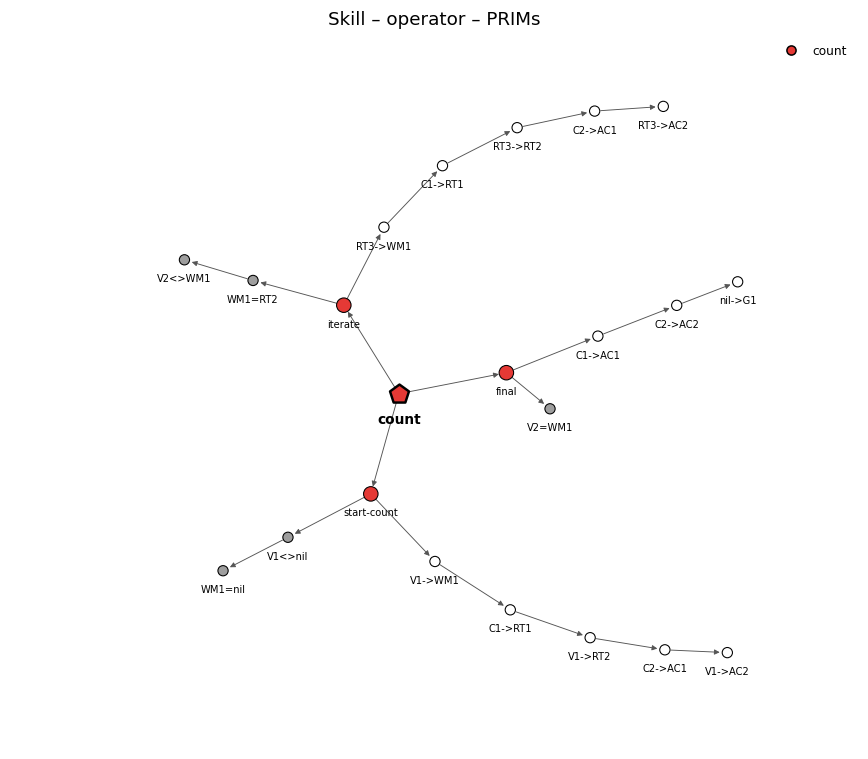

In [18]:
ax = s.plot_graph(2, seed=3)

The second and third operators do the rest of the counting: `iterate` continues as long as the final number has not been reached (`V2 <> WM1`), and `final` terminates the count.

```
operator iterate {
    RT2 = WM1
    V2 <> WM1
   ==>
    RT3 -> WM1
    count-fact -> RT1
    RT3 -> RT2
    say -> AC1
    RT3 -> AC2
}

operator final {
    V2 = WM1
   ==>
    say -> AC1
    stop -> AC2
    nil -> G1
}
```

### Facts

The `define facts` block defines facts that are put into declarative memory. Each list in parentheses becomes a chunk: the first item is the name of the chunk, the remaining items go into its slots. `(cf1 count-fact one two)` becomes:

In [21]:
s.chunk("cf1")

cf1
  isa  fact
  slot1  count-fact
  slot2  one
  slot3  two

Total activation = 2.217
Baselevel activation = 2.456  (fixed 1.000, refs 1)
Current noise = -0.239
Total spreading activation = 0.000

Spreading activation calculation

### Actions

Although we have specified that the model should "say" things, we haven't said what it means to say something. Here we do not really care, but we do want the action to take a certain amount of time:

```
define action say {
  latency: 0.3
  noise: 0.1
  distribution: uniform
  output: Saying
}
```

The latency to say something is 0.3 ± 0.1 seconds, with a uniform distribution of the noise. The action shows up in the trace as "Saying".

### The script

The final part is a script that runs the task:

```
define script {
    digits = ["one","two","three","four","five","six","seven","eight","nine","ten"]
    start = random(3)
    end = start + 1 + random(3)
    print("Counting from",digits[start],"to",digits[end])
    screen(digits[start],digits[end])
    run-until-action("say","stop")
    issue-reward()
    trial-end()
}
```

The syntax is similar to C-style languages, so it should speak for itself (to some extent; details are in the `Reference` notebook). The script defines an array of the numbers one through ten and picks a random start and end number. `screen` puts the selected numbers in the V buffer (`digits[start]` in V1 and `digits[end]` in V2). It then lets the model run until it carries out the action "say stop", issues a reward to the model, and ends the trial.

**The same model in Python.** pyprims can also express a model with a Python API, in which the script is an ordinary Python function. You will not need this for the tutorial, but it can be convenient when the experiment is complicated. `s.to_python()` shows the count model in that form:

In [24]:
print(s.to_python())

"""PRIMs model converted from model.prims by pyprims.convert."""
from pyprims import Task

task = Task('count',
            initial_skills=['count'],
            default_activation=1.0,
            ol=True,
            rt=-2.0,
            lf=0.2,
            default_operator_self_assoc=0.0,
            egs=0.05,
            retrieval_reinforces=True)

skill_count = task.skill('count')
skill_count.operator('start-count', '''
         V1 <> nil  // There has to be an input with the starting number
         WM1 = nil  // Working Memory should be empty
        ==>
         V1 -> WM1 // Copy the start number to working memory
         count-fact -> RT1 // Start retrieving the next number
         V1 -> RT2
         say -> AC1 // Say the current number
         V1 -> AC2
    ''')
skill_count.operator('iterate', '''
         RT2 = WM1
         V2 <> WM1
        ==>
         RT3 -> WM1
         count-fact -> RT1
         RT3 -> RT2
         say -> AC1
         RT3 ->AC2
    ''')
skill_count.o

Operator bodies stay in PRIM notation in both forms, because that notation is the theory's vocabulary. The script functions become methods of `m`, with `-` written as `_` (`run-until-action` is `m.run_until_action`).

### The zero slot

Up to now we have done all operations on slots in the buffers. But what if we want to refer to the chunk as a whole? If you have just retrieved `cf1`, you can access `count-fact`, `one` and `two` in RT1, RT2 and RT3. To access `cf1` itself we have the **zero slot**, RT0. It is not really a slot, but refers to the chunk as a whole. As a consequence, putting nil in the zero slot, for example with `nil -> WM0`, clears the whole buffer. In the case of `nil -> WM0` the chunk is entered into declarative memory, which is a way to create new chunks.

## The PRIMs execution cycle

Operators only move information around within the workspace. It is up to the modules to carry out actions that result from this. The execution cycle is therefore:

1. Retrieve the operator with the highest activation.
2. Check the conditions of that operator. If a condition is not satisfied, retrieve the operator with the next highest activation and try again.
3. Carry out the actions of the operator (i.e., move information between slots in the workspace).
4. Based on the new state of the workspace, let all the modules perform their function in parallel: retrieval from memory, consolidation of the item in working memory, and/or an action. The result may change the content of the buffers again: a retrieval is placed in the retrieval buffer, and some actions change the input.

## Running a model

Everything you do with a model is a method of the session:

| to … | use |
|---|---|
| load a model | `s.load("count.prims")`, or a `%%prims s` cell |
| step through a trial | `s.step()` (one half step: an operator, or the module actions after it); `s.step_operator()` |
| run trials | `s.run(1)`, `s.run(10)`, `s.run(100)` |
| start again | `s.reset()` (a fresh model with the current task), `s.clear()` (forget everything) |
| see the trace | `print(s.trace(level))` |
| see the loaded tasks, or switch task | `s.tasks()`, `s.select_task(name)` |
| see the buffers | `s.buffers()` |
| see declarative memory | `s.dm()`, `s.chunk(name)` |
| see how the last retrieval was decided | `s.conflict_set()` |
| plot the results | `s.plot_results()` |
| plot the task graph | `s.plot_graph(1)`, `s.plot_graph(2)` |
| run a batch file | `s.batch("file.bprims")` |

If you prefer buttons, the **dashboard** shows all of this at once; it is introduced at the end of this section.

### Stepping through a trial

One `step()` is one half step. The first selects and executes an operator; `buffers()` then shows the selected operator, the buffers before the operator (left), how the operator changed them (middle), and how the module actions changed them (right, after the next step):

In [28]:
s.step()
s.buffers()

Operator
  start-count
  Conditions: V1<>nil WM1=nil
  Actions: V1->WM1 C1->RT1 V1->RT2 C2->AC1 V1->AC2
  Constants:
  C1 count-fact
  C2 say
Input
  V1 three
  V2 four
Goal
  G0 currentGoalChunk0
  G1 count
New imaginal
  WM0 imaginal4
  WM1 three

The next step carries out the module actions: the retrieval of the next count fact, the `say` action, and a new chunk in working memory.

In [31]:
s.step()
s.buffers()

Operator
  start-count
  Conditions: V1<>nil WM1=nil
  Actions: V1->WM1 C1->RT1 V1->RT2 C2->AC1 V1->AC2
  Constants:
  C1 count-fact
  C2 say
Input
  V1 three
  V2 four
Action
  AC1 say
  AC2 three
Goal
  G0 currentGoalChunk0
  G1 count
Retrieval request
  RT0 retrievalR5
  RT1 count-fact
  RT2 three
New harvest
  RT0 cf3
  RT1 count-fact
  RT2 three
  RT3 four
New imaginal
  WM0 imaginal4
  WM1 three

### The trace

`s.trace(level)` returns the trace of the current (or last) trial. There are five levels of detail: 1 operators only, 2 adds module actions, 3 adds the productions that carry out the PRIMs, 4 adds production compilation, 5 shows everything. Let us finish this trial and look at it with level 3:

In [34]:
s.run(1)    # finishes the trial that is under way
print(s.trace(3))

Counting from three to four 
0.00  Starting new trial
0.00  *** Retrieved operator start-count with latency 0.001
0.00  Firing V1<>nil
0.05  Firing WM1=nil
0.35  Firing V1->WM1
0.65  Firing C1->RT1
0.95  Firing V1->RT2
1.25  Firing C2->AC1
1.55  Firing V1->AC2
1.85  Retrieving cf3 (latency = 0.049)
1.85  Saying three  (latency = 0.339)
2.19  *** Retrieved operator iterate with latency 0.001
2.19  Firing WM1=RT2
2.24  Firing V2<>WM1
2.54  Firing RT3->WM1
2.84  Firing C1->RT1
3.14  Firing RT3->RT2
3.44  Firing C2->AC1
3.74  Firing RT3->AC2
4.04  Retrieving cf4 (latency = 0.051)
4.04  Saying four  (latency = 0.373)
       4.41  *** Retrieved operator start-count with latency 0.001
       4.41  Firing V1<>nil
       4.46  Firing WM1=nil
       4.76  Operator start-count1112 failed
4.76  *** Retrieved operator final with latency 0.001
4.76  Firing V2=WM1
4.81  Firing C1->AC1
5.11  Firing C2->AC2
5.41  Firing nil->G1
5.71  Saying stop  (latency = 0.252)
5.97  End of trial


The number on the left is time. At time 0 the model retrieves the `start-count` operator. It then carries out the operator by firing a production rule for each individual PRIM. After the last PRIM has been carried out, the modules do their actions in parallel: the retrieval module retrieves the next count fact, the action module says the number, and the imaginal (working memory) module makes a new chunk to store the count. They each have their own latency, and the longest one determines when the model continues. Anything in the trace that is indented belongs to an operator that **failed**: it has no impact on execution, except for taking up time. As you can see, the model is pretty slow to count, taking several seconds.

Level 5 shows everything, including the **conflict set**: for each operator retrieval, all competing operators with their activations, and why the ones that were tried did not match. Only the start of the trace is shown here:

In [37]:
print(s.trace(5)[:2500])

Counting from three to four 
0.00  Starting new trial
0.00  Conflict Set
0.00    start-count A = 5.837
0.00    final A = 5.265
0.00    iterate A = 4.761
0.00  *** Retrieved operator start-count with latency 0.001
0.00  Firing V1<>nil
0.05  Firing WM1=nil
0.05  Compiling V1<>nil;WM1=nil
0.35  Firing V1->WM1
0.35  Compiling WM1=nil;V1->WM1
0.65  Firing C1->RT1
0.65  Compiling V1->WM1;C1->RT1
0.95  Firing V1->RT2
0.95  Compiling C1->RT1;V1->RT2
1.25  Firing C2->AC1
1.25  Compiling V1->RT2;C2->AC1
1.55  Firing V1->AC2
1.55  Compiling C2->AC1;V1->AC2
1.85  Retrieving cf3 (latency = 0.049)
1.85  Saying three  (latency = 0.339)
2.19  Conflict Set
2.19    iterate A = 5.914
2.19    final A = 5.470
2.19    start-count A = 4.296
2.19  *** Retrieved operator iterate with latency 0.001
2.19  Firing WM1=RT2
2.24  Firing V2<>WM1
2.24  Compiling WM1=RT2;V2<>WM1
2.54  Firing RT3->WM1
2.54  Compiling V2<>WM1;RT3->WM1
2.84  Firing C1->RT1
2.84  Compiling RT3->WM1;C1->RT1
3.14  Firing RT3->RT2
3.14  Compi

For each retrieved operator the trace shows all competing operators with their activations. Of those competing operators, only those are tried in which the first production that checks conditions matches. Initially, the only productions are productions that check or execute a single PRIM. But the learning mechanism of **production compilation** learns productions that execute combinations of PRIMs (the "Compiling" lines).

### The conflict set

A better way to see how conflicts are resolved is `s.conflict_set()`. It shows the candidates of the last retrieval in order of activation; click a name (in Jupyter) to see how its activation is made up of base-level activation, spreading activation and noise. Let us step to the next operator selection:

In [40]:
s.step_operator()   # steps until an operator and its module actions are done
s.step()            # selects the next operator: its retrieval is the last retrieval
s.conflict_set()

iterate                           5.460  <- selected
final                             5.406
start-count                       4.826

The breakdown of a single chunk, here the first count fact, is shown by `s.chunk`. See the details on activation at the end of this notebook.

In [43]:
s.chunk("cf2")

cf2
  isa  fact
  slot1  count-fact
  slot2  two
  slot3  three

Total activation = 1.604
Baselevel activation = 1.208  (fixed 1.000, refs 1)
Current noise = 0.395
Total spreading activation = 0.000

Spreading activation calculation
Spreading from goal buffer, spreading parameter = 1.000

`s.dm()` shows all of declarative memory as a table, sorted by activation; you can filter it by chunk type (`type="operator"`), or by a text the chunk name contains (here the count facts):

In [46]:
s.dm(contains="cf")

,type,activation,base_level,spreading,references,fan,slots
name,,,,,,,
cf2,fact,2.078974,1.208299,0.0,1,0,slot1=count-fact slot2=two slot3=three
cf4,fact,1.828476,1.380601,0.0,2,0,slot1=count-fact slot2=four slot3=five
cf1,fact,1.775962,1.380601,0.0,2,0,slot1=count-fact slot2=one slot3=two
cf6,fact,1.718200,1.208299,0.0,1,0,slot1=count-fact slot2=six slot3=seven
cf5,fact,1.639955,1.208299,0.0,1,0,slot1=count-fact slot2=five slot3=six
cf3,fact,1.616737,1.380601,0.0,2,0,slot1=count-fact slot2=three slot3=four
cf7,fact,1.493951,1.208299,0.0,1,0,slot1=count-fact slot2=seven slot3=eight
cf8,fact,1.265453,1.208299,0.0,1,0,slot1=count-fact slot2=eight slot3=nine


### The dashboard

Instead of calling the functions one at a time, you can use the **dashboard**: a panel with buttons that shows the trace, the buffers and all the other views at once. `Dashboard(s)` puts one on top of the session `s`. Run the next cell (the dashboard only appears in a running notebook):

In [49]:
d = Dashboard(s)
d

The dashboard has three parts:

* **The top bar.** A file box with the model files in this folder and a **Load** button; **Step** (one half step), **Step op** (until the next operator is done), **Run** (one trial), **Run 10**, **Run 100** and **Stop**; **Reset** and **Clear All**; and a menu to switch between the loaded tasks. The **Editor** button opens an editor in which you can type or paste a model, load it, convert it to Python, and save it to a file.
* **The trace and the buffers**, side by side. The menu above the trace sets the level of detail.
* **Tabs** with the results chart, the task graph, declarative memory (select a chunk to see how its activation is made up), the conflict set, the learned productions and the task list.

Try it: press **Step** a few times and watch the buffers change, then press **Run 100** and look at the **Chart** tab.

The dashboard and the code cells work on the same session, so you can switch between them. After you change the session in a code cell, call `d.refresh()` to update the dashboard:

In [52]:
s.run(10)
d.refresh()

You can also open a dashboard with a session of its own, for example to explore another model without disturbing `s`. Its session is `d2.s`:

In [55]:
d2 = Dashboard(seed=2)
d2

## Production compilation

The trace at level 4 shows production compilation in action. After `V1<>nil` and `WM1=nil` have been checked, a rule is learned that makes both comparisons in one step. This rule is not used right away. All rules have a **utility**, and the rule with the highest utility is used. Initially there are only rules that each carry out a single PRIM, and they all have a utility of 2.0 (set with the `primU:` parameter). Newly learned productions start with a utility of 0.0 (the `nu:` parameter). Whenever PRIMs selects a production rule, it adds logistic noise to the utilities (scaled by `egs:`, default 0.05) and picks the rule with the highest value.

Whenever a rule successfully leads to the execution of an operator, its utility is adjusted:

$$U_{t+1} = U_t + \alpha\,(\textrm{Payoff} - U_t)$$

Payoff is the reward parameter (`procedural-reward:`, default 4.0) minus the time needed after executing the production to finish the operator. The parameter $\alpha$ controls the learning speed (`alpha:`, default 0.1). Learning only applies to rules that consist of multiple PRIMs: the utility of rules that carry out a single PRIM stays fixed at `primU`.

Obviously, a new rule has little chance to compete with the rule it was learned from. Therefore, every time a production is relearned, its utility is increased by

$$U_{t+1} = U_t + \alpha\,(U_\textrm{parent} - U_t)$$

the same equation as before, but with the payoff replaced by the utility of the parent. This ensures that the utility gradually approaches the utility of the parent, increasing the odds that it will eventually be selected (and evaluated).

Production compilation speeds up the model. Carrying out an operator takes the time needed to retrieve the operator (typically very short) plus the time needed to fire the production rules that carry it out. The first of these takes 50 ms, but each subsequent one takes 300 ms (the `dat:` and `production-prim-latency:` parameters). After sufficient learning, a production is learned that checks all conditions and carries out all actions in a single rule. Let us run the model 100 times and look at the result:

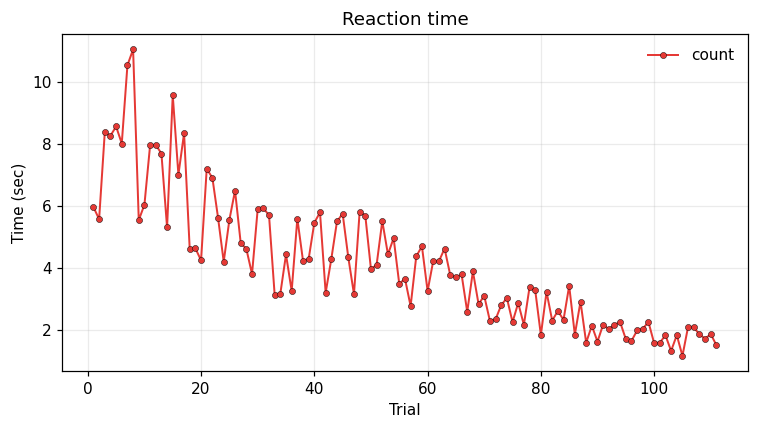

In [58]:
s.run(100)
ax = s.plot_results()

The trace of the last trial now shows rules that carry out several PRIMs at once:

In [61]:
print(s.trace(3))

Counting from two to three 
458.91  Starting new trial
458.92  *** Retrieved operator start-count with latency 0.004
458.92  Firing V1<>nil;WM1=nil;V1->WM1;C1->RT1
458.97  Firing V1->RT2;C2->AC1;V1->AC2
459.27  Retrieving cf2 (latency = 0.025)
459.27  Saying two  (latency = 0.282)
459.55  *** Retrieved operator iterate with latency 0.001
459.55  Firing WM1=RT2;V2<>WM1;RT3->WM1;C1->RT1;RT3->RT2;C2->AC1;RT3->AC2
459.60  Retrieving cf3 (latency = 0.020)
459.60  Saying three  (latency = 0.395)
460.00  *** Retrieved operator final with latency 0.001
460.00  Firing V2=WM1;C1->AC1;C2->AC2;nil->G1
460.05  Saying stop  (latency = 0.381)
460.43  End of trial


`s.productions()` lists the learned productions with their utilities:

In [64]:
s.productions().head(10)

,name,utility,size,above_primU,task,remaining,parents
0,WM1=RT2;V2<>WM1;RT3->WM1;C1->RT1;RT3->RT2;C2->...,3.945314,7,True,count,,WM1=RT2;V2<>WM1;RT3->WM1;C1->RT1 + RT3->RT2;C2...
1,V2=WM1;C1->AC1;C2->AC2;nil->G1,3.929337,4,True,count,,V2=WM1;C1->AC1 + C2->AC2;nil->G1
2,C2->AC2;nil->G1,3.693014,2,True,count,,
3,C2->AC1;RT3->AC2,3.690845,2,True,count,,
4,RT3->RT2;C2->AC1;RT3->AC2,3.689063,3,True,count,,C2->AC1;RT3->AC2
5,V1->RT2;C2->AC1;V1->AC2,3.686308,3,True,count,,C2->AC1;V1->AC2
6,V2=WM1;C1->AC1,3.640802,2,True,count,C2->AC2;nil->G1,
7,WM1=RT2;V2<>WM1;RT3->WM1;C1->RT1,3.639614,4,True,count,RT3->RT2;C2->AC1;RT3->AC2,WM1=RT2;V2<>WM1 + RT3->WM1;C1->RT1
8,V1<>nil;WM1=nil;V1->WM1;C1->RT1,3.570290,4,True,count,V1->RT2;C2->AC1;V1->AC2,V1<>nil;WM1=nil + V1->WM1;C1->RT1
9,RT3->RT2;C2->AC1,3.391161,2,True,count,RT3->AC2,


## Modeling transfer

One of the goals of PRIMs is to model transfer. The general idea is that productions that are learned for one task can be reused for another task. We therefore need a second model: `semantic.prims`. The semantic model judges relationships between animals and animal categories, and answers questions like "Is a lion an animal?". It uses these facts:

```
define facts {
    (sem1  property  lion  mammal)
    (sem2  property  mammal  animal)
    (sem3  property  animal living-thing)
    (sem4  property  plant living-thing)
    (sem5  property  tulip plant)
    (sem6  property  bird animal)
    (sem7  property  tweety bird)
    (sem8  property  robin bird)
}
```

Answering the question involves two steps: first retrieve that a lion is a mammal, and then that a mammal is an animal. Even though this model is semantically different from count, it shares the same type of iteration, so the operators are similar:

In [67]:
show_model("semantic.prims")

// Simple semantic model
//

define task semantic {
    initial-skills: (semantic)
    ol: t
    rt: -2.0
    lf: 0.2
    default-operator-self-assoc: 0.0
    default-activation: 1.0
}

define skill semantic {
    operator start-semantic {
        V1 <> nil
        WM1 = nil
     ==>
        V1 -> WM1
        property -> RT1
        V1 -> RT2
        subvocalize -> AC1
        V1 -> AC2
    }

    operator move-up-tree {
        RT2 = WM1
        V2 <> WM1
        ==>
        RT3 -> WM1
        property -> RT1
        RT3 -> RT2
        subvocalize -> AC1
        RT3 -> AC2
    }

    operator say-yes {
        V2 = WM1
        ==>
        say -> AC1
        yes -> AC2
        stop -> G1
    }

    operator say-no {
        V2 <> WM1
        RT1 = error
        ==>
        say -> AC1
        no -> AC2
        nil -> G1
    }
}

define action subvocalize {
    latency: 0.2
    noise: 0.08
    distribution: uniform
    output: Subvocalizing
}

define action say {
    latency: 0.3
    noi

The first two operators are the same as in the counting model, except that the constants are different. Once the operators are translated into chunks, the conditions and actions are identical. The last two operators are different. If the target category matches the retrieved category, the model answers "yes", which is slightly different from finalizing the count. If the proposition does not hold, the model will hit a retrieval failure at some point; on a failure, the first slot of the retrieval buffer is set to `error` (which is matched by `RT1 = error`).

Here is a run of the semantic model on its own. We use a new session, `sem`:

In [70]:
sem = Session(seed=2)
sem.load("semantic.prims")
sem.run(1)
print(sem.trace(3))

Is mammal a living-thing ? 
0.00  Starting new trial
0.00  *** Retrieved operator start-semantic with latency 0.001
0.00  Firing V1<>nil
0.05  Firing WM1=nil
0.35  Firing V1->WM1
0.65  Firing C1->RT1
0.95  Firing V1->RT2
1.25  Firing C2->AC1
1.55  Firing V1->AC2
1.85  Retrieving sem2 (latency = 0.037)
1.85  Subvocalizing mammal  (latency = 0.193)
2.05  *** Retrieved operator move-up-tree with latency 0.001
2.05  Firing WM1=RT2
2.10  Firing V2<>WM1
2.40  Firing RT3->WM1
2.70  Firing C1->RT1
3.00  Firing RT3->RT2
3.30  Firing C2->AC1
3.60  Firing RT3->AC2
3.90  Retrieving sem3 (latency = 0.085)
3.90  Subvocalizing animal  (latency = 0.195)
       4.09  *** Retrieved operator start-semantic with latency 0.001
       4.09  Firing V1<>nil
       4.14  Firing WM1=nil
       4.44  Operator start-semantic1718 failed
       4.44  *** Retrieved operator say-no with latency 0.001
       4.44  Firing V2<>WM1
       4.49  Firing RT1=C1
       4.79  Operator say-no1920 failed
4.79  *** Retrieved ope

### Measuring transfer

How do we assess transfer between these two models? A first option is to look at the overlap of PRIMs between them. The task graph (`plot_graph`) shows skills, operators and PRIMs. Load both models into one session; nodes that are used by both tasks get a yellow halo:

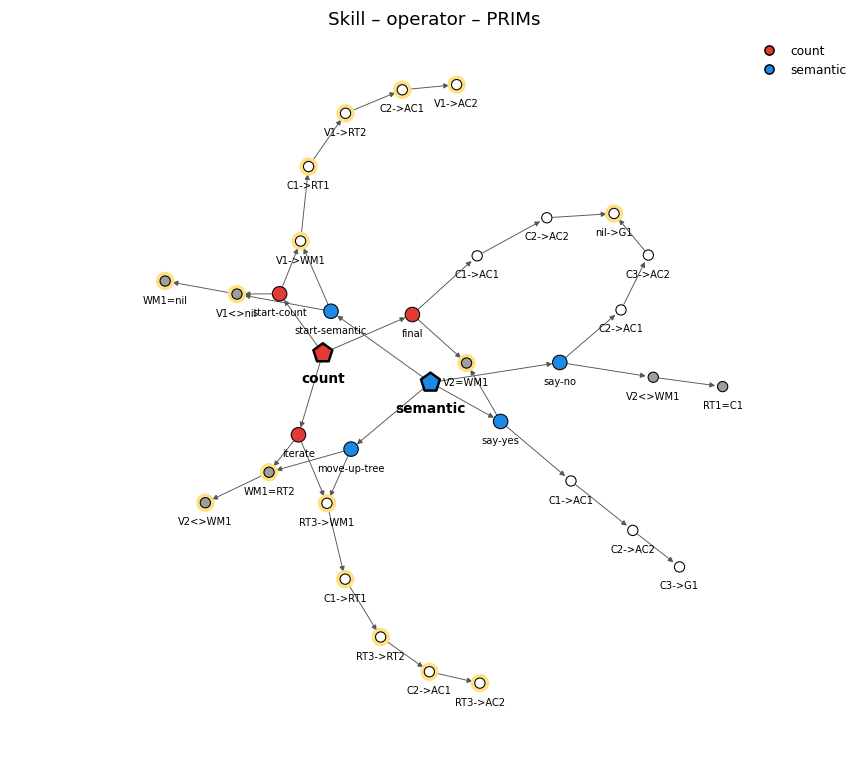

In [73]:
both = Session(seed=4)
both.load("count.prims")
both.load("semantic.prims")
ax = both.plot_graph(2, seed=3)

To get a real sense of the amount of transfer, we have to run the models. We first run count a number of times, and then semantic. Then we run semantic without prior training. This takes three lines, one per condition:

* `load` a second task **adds** it to the model, so declarative memory and the learned productions carry over;
* `reset()` gives a fresh model with only the current task (semantic): the control condition.

Each load or reset starts a new line in the results graph. Lines are colored by task, and a second line of the same task is dashed; `labels` gives each line a name of your own.

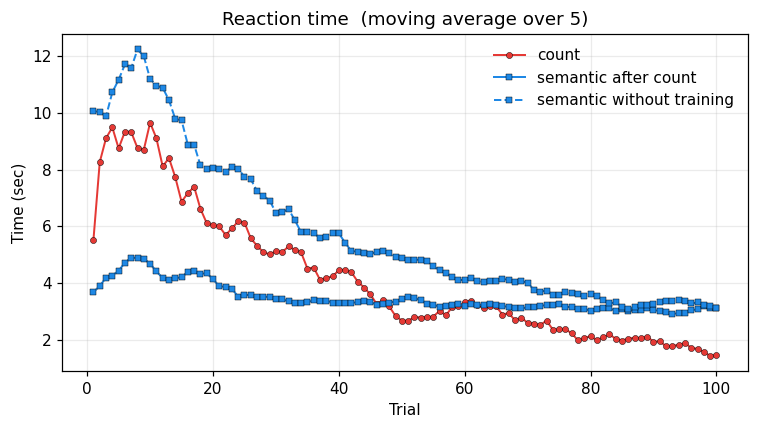

In [76]:
t = Session(seed=5)
t.load("count.prims");    t.run(100)      # train on count
t.load("semantic.prims"); t.run(100)      # semantic after count
t.reset();                t.run(100)      # semantic without prior training
ax = t.plot_results(average_window=5, labels=["count", "semantic after count", "semantic without training"])

Semantic after count starts much faster than semantic without training: that difference is the transfer. The trace of a semantic trial after training on count shows that it uses productions compiled while counting:

In [79]:
t2 = Session(seed=6)
t2.load("count.prims");    t2.run(100)
t2.load("semantic.prims"); t2.run(1)
print(t2.trace(3))

Is lion a living-thing ? 
413.87  Starting new trial
413.87  *** Retrieved operator start-semantic with latency 0.001
413.87  Firing V1<>nil;WM1=nil;V1->WM1
413.92  Firing C1->RT1;V1->RT2
414.22  Firing C2->AC1;V1->AC2
414.52  Retrieving sem1 (latency = 0.047)
414.52  Subvocalizing lion  (latency = 0.278)
       414.80  *** Retrieved operator say-no with latency 0.000
       414.80  Firing V2<>WM1
       414.85  Firing RT1=C1
       415.15  Operator say-no26652666 failed
415.15  *** Retrieved operator move-up-tree with latency 0.002
415.15  Firing WM1=RT2;V2<>WM1;RT3->WM1;C1->RT1;RT3->RT2;C2->AC1;RT3->AC2
415.20  Retrieving sem2 (latency = 0.044)
415.20  Subvocalizing mammal  (latency = 0.201)
       415.40  *** Retrieved operator say-no with latency 0.001
       415.40  Firing V2<>WM1
       415.45  Firing RT1=C1
       415.75  Operator say-no26732674 failed
415.75  *** Retrieved operator move-up-tree with latency 0.002
415.75  Firing WM1=RT2;V2<>WM1;RT3->WM1;C1->RT1;RT3->RT2;C2->AC1;

### Batch runs

A single run is noisy. To collect proper data we run the models many times and average. This is what **batch files** are for. `testbatch.bprims` does what we just did by hand, ten times:

In [82]:
print(open("testbatch.bprims").read())

repeat 10
reset
run count traincount 100
run semantic semantictransfer 100
reset
run semantic semanticcontrol 100



`s.batch(file)` runs it and returns the output lines (pass `out_path=` to also write a file); `read_batch` turns them into a pandas DataFrame, and `plot_batch` plots the mean trial time per block of trials, with ±1 standard error over the repeats. The format of the batch file and of the output is described in Unit 3 and in the `Reference` notebook. This takes a few seconds.

In [85]:
out = s.batch("testbatch.bprims", seed=1)
data = read_batch(out)
data.head()

,repeat,task,label,trial,time,event,p1,p2,p3,in0,in1,in2,in3,in4,firings
0,0,count,traincount,1,2.215568,action,say,one,void,void,void,void,void,void,7
1,0,count,traincount,1,4.462545,action,say,two,void,void,void,void,void,void,7
2,0,count,traincount,1,5.648162,action,say,stop,void,void,void,void,void,void,4
3,0,count,traincount,1,5.648162,trial-end,success,void,void,void,void,void,void,void,0
4,0,count,traincount,2,2.062306,action,say,one,void,void,void,void,void,void,7


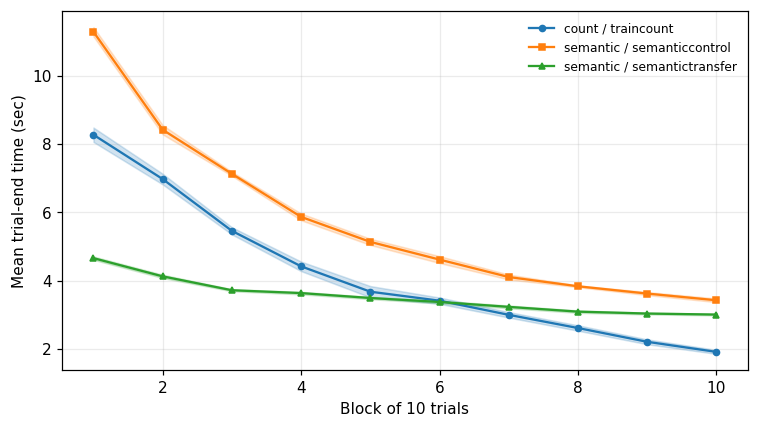

In [86]:
ax = plot_batch(data, block=10)

Because the result is a DataFrame, any analysis is a few lines of pandas. For example, the mean time of the first 10 semantic trials with and without training on count:

In [88]:
ends = data[(data.event == "trial-end") & (data.trial <= 10)]
ends.groupby("label").time.mean().round(2)

label
semanticcontrol     11.30
semantictransfer     4.66
traincount           8.28
Name: time, dtype: float64

### Batch runs in Python

A batch file is convenient, but it can only do what its handful of commands allow. You can do the same in Python, with the `Model` class that sits underneath a `Session`. Then the experiment is ordinary code: you can loop over conditions, change the order of tasks, compute something after every trial, or stop when a criterion is reached.

The building blocks are:

| batch file | Python |
|---|---|
| `repeat 10` | `for rep in range(10):` |
| `reset` | `m = Model(seed=..., trace=False, batch_mode=True)`: a fresh model |
| `run count traincount 100` | `m.load("count.prims")`, then `m.run_trial()` 100 times |

`trace=False` switches off the trace, which makes the model faster, and `batch_mode=True` keeps the script's `print` output out of the notebook. After each `m.run_trial()`, `m.results[-1]` is the result of that trial (its duration, or the value of `plot-point`), and `m.output_data` holds its events: the same events that end up in the batch output.

`run_trials(model, n, task, **fields)` does the `run` line for you: it loads the task (or switches back to it, if it is already loaded, so that what the model learned carries over), runs it `n` times, and returns one record per trial. Each record has the trial number, the task, the `result`, and the `outcome` (`success`, or `fail` if no operator matched), plus any fields you pass, such as `repeat=` and `label=`. A list of records becomes a pandas DataFrame directly.

With it, `testbatch.bprims` becomes a loop. Each `Model` gets its own seed from one random generator, so the whole simulation is reproducible:

In [90]:
import random
import pandas as pd
from pyprims import Model, run_trials

In [95]:
master = random.Random(1)
rows = []
for rep in range(10):
    m = Model(seed=master.random(), trace=False, batch_mode=True)      # reset
    rows += run_trials(m, 100, "count.prims", repeat=rep, label="traincount")
    rows += run_trials(m, 100, "semantic.prims", repeat=rep, label="semantictransfer")
    m = Model(seed=master.random(), trace=False, batch_mode=True)      # reset
    rows += run_trials(m, 100, "semantic.prims", repeat=rep, label="semanticcontrol")

pydata = pd.DataFrame(rows)
print(pydata.head())
pydata[pydata.trial <= 10].groupby("label").result.mean().round(2)

   repeat       label  trial   task    result  outcome
0       0  traincount      1  count  5.966164  success
1       0  traincount      2  count  5.575390  success
2       0  traincount      3  count  8.376581  success
3       0  traincount      4  count  8.265624  success
4       0  traincount      5  count  8.564204  success


label
semanticcontrol     11.24
semantictransfer     4.58
traincount           8.24
Name: result, dtype: float64

The numbers are close to those of the batch file above; they are not identical, because the two runs use different random numbers. Plotting the learning curves per block of 10 trials is a `groupby` away:

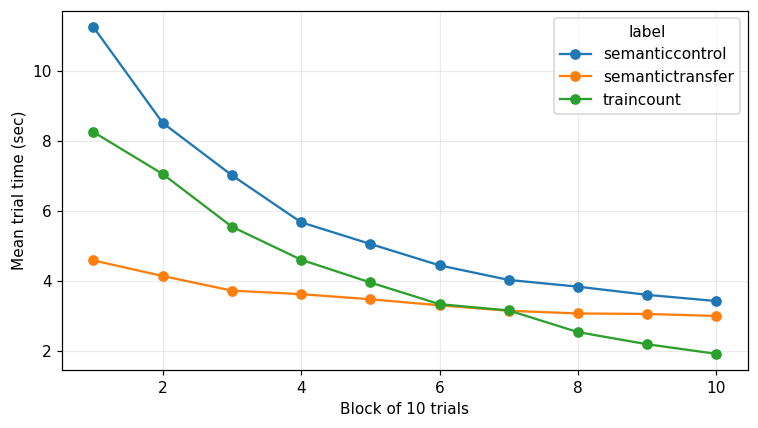

In [97]:
blocks = pydata.assign(block=(pydata.trial - 1) // 10 + 1).groupby(["label", "block"]).result.mean().unstack(0)
with figure(1, 1, figsize=(7, 4)) as ax:
    blocks.plot(ax=ax, marker="o")
    ax.set_xlabel("Block of 10 trials"); ax.set_ylabel("Mean trial time (sec)"); ax.grid(alpha=0.25)

If you need more than the trial results, for example which answer the model gave, use `events=True`: you then get one record per event, with the same columns as the batch output. Each event has a type (`action`, `trial-end` or `data-line`), the action itself in `p1`, `p2` and `p3`, and the time within the trial:

In [101]:
m = Model(seed=1, trace=False, batch_mode=True)
events = pd.DataFrame(run_trials(m, 2, "semantic.prims", events=True))
events[["trial", "event", "p1", "p2", "time"]]

,trial,event,p1,p2,time
0,1,action,subvocalize,tulip,2.130645
1,1,action,subvocalize,plant,4.533915
2,1,action,subvocalize,living-thing,7.294183
3,1,action,say,no,10.159301
4,1,trial-end,success,void,10.159301
5,2,action,subvocalize,tulip,2.124626
6,2,action,subvocalize,plant,4.155017
7,2,action,subvocalize,living-thing,6.934872
8,2,action,say,no,10.090697
9,2,trial-end,success,void,10.090697


Now for something that a batch file cannot express easily: how does the amount of transfer depend on the amount of training? We train count for 0, 10, 25, 50 or 100 trials, then measure the mean time of the first 10 semantic trials, averaged over 10 model runs per condition:

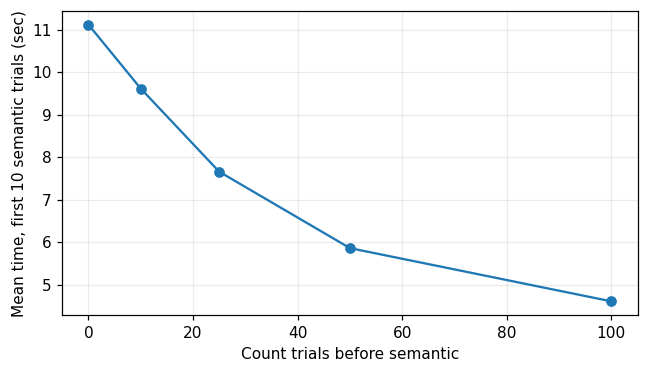

n_train
0      11.12
10      9.61
25      7.66
50      5.86
100     4.61
Name: result, dtype: float64

In [104]:
master = random.Random(2)
rows = []
for n_train in [0, 10, 25, 50, 100]:
    for rep in range(10):
        m = Model(seed=master.random(), trace=False, batch_mode=True)
        if n_train > 0:
            run_trials(m, n_train, "count.prims")
        rows += run_trials(m, 10, "semantic.prims", repeat=rep, n_train=n_train)

dose = pd.DataFrame(rows).groupby("n_train").result.mean()
with figure(1, 1, figsize=(6, 3.5)) as ax:
    ax.plot(dose.index, dose.values, marker="o")
    ax.set_xlabel("Count trials before semantic"); ax.set_ylabel("Mean time, first 10 semantic trials (sec)")
    ax.grid(alpha=0.25)
dose.round(2)

The same pattern works for any manipulation: loop over parameter values (`m.set_parameter("lf:", "0.3")` sets a parameter; do it after loading the task, because loading a task sets that task's own parameters), over orders of tasks, or over stimulus lists read from a data file.

## Perception and action

PRIMs uses a simplified version of ACT-R's perception and motor modules. Some of the precision is lost, but on the other hand it is easier to program the experiment part of the model.

For the assignment below we are going to build two models of addition by counting. The first works through mental operations only; the second assumes that one of the two counters is maintained with the fingers. Each time the model says a number, it also sticks up an additional finger, and the total number of fingers is available to perception. This needs a slightly more elaborate script that changes perception on the basis of actions (from `add-fingers.prims`):

```
define script {
    digits = ["zero","one","two","three","four","five","six","seven","eight","nine","ten"]
    num1 = random(4) + 1
    num2 = random(4) + 1
    print("Adding",digits[num1],"and",digits[num2])
    screen(digits[num1],digits[num2])
    done = 0
    fingers = 0
    while (!done) {
        run-until-action()
        ac = last-action()
        if (ac[0] == "say") {
            fingers = fingers + 1
            screen(digits[num1],digits[num2],digits[fingers])
        }
        if (ac[0] == "answer") {
            done = 1
        }
    }
    issue-reward()
    trial-end()
}
```

The script picks two random numbers between one and four and displays them. It then loops until the model uses "answer" as an action. `run-until-action()` runs the model until it takes any action; `last-action()` returns an array with the last action. If its first element is "say", we put up an extra finger and add it to the input (it goes into V3). If it is "answer", we are done (the script language has no Booleans, but uses 0 as false and any non-zero number as true).

*Models in Python.* In the Python form of a model, there is a shorter way to do this. Instead of the script catching each action and responding to it, an action can call a Python function directly: a function registered with `@task.action_function` is called whenever an operator puts its name in AC1. For the fingers model, a function `say` would raise a finger and update the screen, and the script would only need `m.run_until_action("answer")`. Section 5 of the Reference notebook explains how this works.

## Assignment

The assignment is to add a model of addition by counting to the existing two models, and to assess the transfer between counting and addition.

There are two possible solutions to explore. The first keeps track of two numbers in WM. The two numbers to be added are perceptual input, and two WM slots hold the current count and the current sum.

1. The first operator initializes the process by putting the first addend (in V1) into WM1, and `zero` in WM2. It then makes a retrieval request for a count fact about the number in V1.
2. The second operator harvests a retrieved count fact that matches WM1, updates the number in WM1, and issues a count-fact retrieval request for WM2.
3. A third operator harvests a count-fact retrieval that matches WM2, checks whether WM2 is not equal to the second addend (in V2), and issues a count-fact retrieval for WM1. It also updates WM2.
4. A fourth operator checks whether the count in WM2 equals V2, and gives the contents of WM1 as an answer.

Write the operators in the cell below and run it. The cell holds the contents of `add.prims`: the task, the facts (note that they include `zero`) and a script that runs the model until it gives an "answer" action. Make sure that the last action of your model is `answer`, followed by the result!

In [109]:
%%prims add --reset
// Add numbers by counting
// The script assumes that the final action is "answer"

define task add {
    initial-skills: (add)
    default-activation: 1.0
}

define skill add {
    // Write your four operators here
}

define facts {
    (cf0 count-fact  zero  one :activation 3.0)
    (cf1 count-fact  one  two :activation 3.0)
    (cf2 count-fact  two  three :activation 3.0)
    (cf3  count-fact  three  four :activation 3.0)
    (cf4  count-fact  four  five :activation 3.0)
    (cf5  count-fact  five  six :activation 3.0)
    (cf6  count-fact  six  seven :activation 3.0)
    (cf7  count-fact  seven  eight :activation 3.0)
    (cf8  count-fact  eight  nine :activation 3.0)
    (cf9  count-fact  nine  ten :activation 3.0)
}

define script {
    digits = ["zero","one","two","three","four","five","six","seven","eight","nine","ten"]
    num1 = random(4) + 1
    num2 = random(4) + 1
    print("Adding",digits[num1],"and",digits[num2])
    screen(digits[num1],digits[num2])
    run-until-action("answer")
    issue-reward()
    trial-end()
}

Loaded task 'add' into add (tasks: add)


Test the model with one trial and look at the trace. As long as the skill has no (working) operators, no operator matches, and the trial ends without an answer. The session then warns you that the model stopped because no operator matched.

In [112]:
add.run(1)
print(add.trace(2))

Adding four and four 
0.00  Starting new trial
0.00     No matching operator found
1.48  End of trial


/var/folders/hp/fxvnkpp08xjfy70059bk39_80000gn/T/ipykernel_85682/1646352552.py:1: NoOperatorWarning: In 1 of 1 trial the model stopped because no operator matched. The rest of the script then ran without the model, so last-action() may be empty. trace(2) shows the last trial.
  add.run(1)


You can also use the Dashboard to run the model, this can be particularly useful if you need to do some debugging.


In [119]:
Dashboard(add)


Once the model works, check how fast it learns, and how much transfer there is from the count model, using the same method as with semantic. The function below runs a task with and without prior training on count and plots both learning curves (`tasks=` restricts the graph to the addition task). A cell model has no file, so we pass the model text (`add.source()`); a file name works as well. If you want to use a batch file instead, copy `testbatch.bprims`, replace `semantic` by the name of your task, and save your model in a `.prims` file with the same name as the task.

In [38]:
def transfer_test(model, train="count.prims", n_train=100, n_test=50, seed=1):
    """Run `model` after training on `train`, and without training; plot both."""
    t = Session(seed=seed)
    t.load(train); t.run(n_train)
    t.load(model); t.run(n_test); trained = t.results     # with training
    t.reset();     t.run(n_test); control = t.results     # control: no training
    t.plot_results(average_window=5, tasks=[t.current_task], labels=[f"after {train}", "without training"])
    print("mean of the first 10 trials: %.2f s after training, %.2f s without training"
          % (sum(trained[:10]) / 10, sum(control[:10]) / 10))

# transfer_test(add.source())     # remove the # when your model works

You will probably conclude that the transfer between counting and this addition model is limited. You can therefore try to build an alternative model **using fingers** (`add-fingers.prims` contains the task and the script above). This model needs only a few operators, and should show more transfer than the "standard" model. Write it in a new `%%prims add_fingers --reset` cell (or edit `add-fingers.prims` and load the file), and use `transfer_test` again. When you compare the two, look at the PRIMs that the addition operators share with the count operators: `plot_graph(2)` with both tasks loaded shows the overlap.

## Details of declarative memory

The standard ACT-R equation for the activation of a chunk $i$ is

$$A_i = B_i + \sum_{k}^{\textrm{sources}} \sum_{j}^{\textrm{slots}} S_{ji} W_k + \textrm{noise}$$

$B_i$ is the base-level activation, which reflects how often the chunk has been recreated in the past. The double summation is the spreading activation from the different buffers (sources) in the workspace. Each buffer spreads an amount of activation $W_k$, set by a global parameter (e.g., `imaginal-activation:` for the imaginal buffer; see the list of parameters in the `Reference` notebook). Each buffer has a number of slots, and the chunk in each slot is a potential source of spreading if it has a non-zero strength of association $S_{ji}$ with chunk $i$. This strength can be set explicitly in the model, but it also gets a value by default whenever a chunk in the buffer is in one of the slots of a chunk in declarative memory. For example, the chunk *three* has a positive association with the chunk that represents 3 + 4 = 7, because *three* is in one of its slots.

The base-level activation follows the standard formula

$$B_i(t) = \ln \sum_k (t - t_k)^{-d}$$

where the $t_k$ are all the moments the chunk was created or accessed, and $d$ is the decay parameter (`bll:`, 0.5 by default). In standard ACT-R, both recreating a chunk and retrieving it reinforce the chunk. In PRIMs, only recreating a chunk in the working memory buffer reinforces it, unless the `retrieval-reinforces:` parameter is `t`.

Because the standard formula is computationally expensive, an approximation is used by default (the `ol:` parameter):

$$B_i(t) = \ln\frac{n}{1-d} - d\,\ln(t - t_0)$$

where $t_0$ is the creation time of the chunk and $n$ the number of references it had during its lifetime.

The strength of association $S_{ji}$ is zero by default, except when chunk $j$ is in a slot of chunk $i$. In that case

$$S_{ji} = S - \ln(\textrm{fan}_j)$$

where $S$ is the maximum associative strength (`mas:`) and $\textrm{fan}_j$ is the number of chunks in which chunk $j$ appears. The idea is that if chunk $j$ appears in many chunks, it is less predictive of chunk $i$, so its association is weaker. (In PRIMs the fan does not count chunk $j$ itself, and $S_{ji}$ never drops below zero.)

When the total activation of a chunk is below the retrieval threshold $\tau$ (`rt:`), retrieval fails. If retrieval succeeds, it takes

$$t_\textrm{retrieval} = F e^{-A_i}$$

where $F$ is the latency factor (`lf:`). A retrieval failure takes $F e^{-\tau}$.

PRIMs adds a few things to the standard equations. First, it handles spreading activation from skills slightly differently. We will discuss this in a later unit, but the equation is

$$A_i = B_i + \sum_{k}^{\textrm{buffers}} \sum_{j}^{\textrm{slots}} S_{ji} W_k + \sum_{k}^{\textrm{skills}} S_{ki} A_k + \textrm{noise}$$

The idea is that every active skill spreads an amount of activation equal to its own activation.

Second, PRIMs has a **default activation**. In most models you add facts that you assume are more or less permanently available to the model; in the count model you don't want the model to forget the count facts. The default activation puts a lower bound on the base-level activation of the chunks defined in the model: if it is well above the retrieval threshold, and the noise is not too large, retrieval always succeeds. It enters the base-level equations as an extra term:

$$B_i(t) = \ln\left(e^{\textrm{default}} + \sum_k (t - t_k)^{-d}\right) \qquad\textrm{or, optimized,}\qquad B_i(t) = \ln\left(e^{\textrm{default}} + \frac{n\,(t - t_0)^{-d}}{1-d}\right)$$

You can check these equations against the model. `s.chunk(name)` shows how the activation of a chunk is made up at this moment:

In [39]:
s.chunk("cf3")

cf3
  isa  fact
  slot1  count-fact
  slot2  three
  slot3  four

Total activation = 2.314
Baselevel activation = 2.496  (fixed 1.000, refs 101)
Current noise = -0.182
Total spreading activation = 0.000

Spreading activation calculation
Spreading from goal buffer, spreading parameter = 1.000

## Other example models

The folder `extra-models` contains some small models used in the PRIMs lecture slides: `name-color`, `aural-vocal` and `type-next` (simple retrieval tasks) and `paired` (a paired-associate template with a batch file). Load them in a session to explore.

**Next:** the `Reference` notebook lists all parameters and script functions. Unit 2 introduces variable binding and models that consist of several skills.